# Where in the cell does a protein work? Predicting it from sequence with a protein language model

**Module 04.1 · my implementation**, Seid Adem

> **The question in plain language.** A human cell is divided into compartments: the **nucleus** (where DNA is),
> the **cytoplasm** (the fluid interior), **mitochondria** (energy production), the **endoplasmic reticulum** and
> **Golgi apparatus** (where proteins are folded, modified and shipped), the **cell membrane** (the outer boundary),
> and the outside world (**secreted** proteins such as hormones and antibodies). A protein only works in the right
> place, so knowing its location hints at its function. It also matters commercially: most drug targets sit on the
> cell membrane, and secreted proteins are where blood biomarkers come from.
>
> Measuring location in the lab takes microscopy experiments, one protein at a time. Predicting it from the
> **amino-acid sequence** alone (the protein's one-letter "text", e.g. `MKTLLV…`) is a classic bioinformatics task.

This notebook reuses the deep-learning tools of [notebook 01](01_pytorch_mlp_pubmed_rct.ipynb) on a completely
different kind of "language":

1. **Builds an honest dataset** from UniProt (via my tested EBI client) using only *experimentally* supported
   locations.
2. **Compares a hand-crafted baseline** (amino-acid composition) with **embeddings from ESM-2**, a protein language
   model ([what an embedding is: Lesson 5](../LESSONS.md)).
3. **Evaluates with cross-validation grouped by protein family**, so the score reflects *new kinds* of proteins.
4. **Adds one piece of biology** (where targeting signals sit in a sequence) and measures what it's worth.

In [1]:
import io
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
import umap
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import AutoModel, AutoTokenizer

from dsls.ebi_api import uniprot
from dsls.protein import aa_composition, coarse_locations
from dsls.textclf import MLPClassifier, make_loader, pick_device, predict_proba, train_with_early_stopping

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="n_jobs value", category=UserWarning)
transformers.logging.set_verbosity_error()
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
CACHE = Path("../../../data/interim")  # git-ignored: embeddings are recomputed, never committed
CACHE.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 0
DEVICE = pick_device()
print("device:", DEVICE)

device: mps


## 1 · Building the dataset: only what was measured

> **In plain language.** UniProt is the world's reference database of proteins, curated at EMBL-EBI. Its
> location annotations come with **evidence codes**: some were measured in an experiment (`ECO:0000269`), others
> were inferred from similar proteins or predicted by software. Training a model on *predictions* would teach it to
> imitate other software, so I keep only experimental statements. I also keep only proteins with **exactly one**
> compartment, so each has one clear answer (many real proteins move between places; that is a harder,
> multi-label problem).

Query: reviewed human proteins (Swiss-Prot), 50–1,000 amino acids long, with at least one experimental location.

In [2]:
query = "organism_id:9606 AND reviewed:true AND length:[50 TO 1000] AND cc_scl_term_exp:*"
fields = "accession,length,cc_subcellular_location,protein_families,sequence"
response = uniprot().get("uniprotkb/stream", params={"query": query, "fields": fields, "format": "tsv"})
raw = pd.read_csv(io.StringIO(response.text), sep="\t")
raw.columns = ["accession", "length", "location_text", "family", "sequence"]
raw["locations"] = raw["location_text"].map(coarse_locations)
print(
    f"{len(raw):,} proteins downloaded (from cache: {response.from_cache}, fetched {response.fetched_at[:10]})"
)
print(
    "experimental compartments per protein:", raw["locations"].map(len).value_counts().sort_index().to_dict()
)

data = raw[raw["locations"].map(len) == 1].reset_index(drop=True)
data["location"] = data["locations"].map(lambda s: next(iter(s)))
# Group = protein (super)family; proteins without a family annotation form their own group.
data["group"] = data["family"].fillna(data["accession"]).str.split(",").str[0]
CLASSES = data["location"].value_counts().index.tolist()
data["y"] = data["location"].map(CLASSES.index)
print(f"\n{len(data):,} proteins with exactly one compartment, {data['group'].nunique():,} family groups")
print(data["location"].value_counts().to_string())

10,040 proteins downloaded (from cache: True, fetched 2026-11-08)
experimental compartments per protein: {0: 2871, 1: 4856, 2: 1923, 3: 318, 4: 52, 5: 18, 6: 2}

4,856 proteins with exactly one compartment, 2,982 family groups
location
nucleus                  1233
cytoplasm                1189
cell membrane             906
mitochondrion             546
secreted                  436
endoplasmic reticulum     362
Golgi apparatus           184


Seven classes, from 1,233 nuclear down to 184 Golgi proteins. As in the abstracts notebook, **macro-F1** (every
class counts equally) is the headline metric, so rare compartments matter as much as common ones.

> **Why group by family?** Proteins in the same family descend from a common ancestor and have similar sequences
> *and* usually the same location. A random split puts family members on both sides, so a model can "recognise
> the relative" instead of learning the targeting rules. That inflates scores, the same trap as the crystal
> structures in [03.2](../../../03_foundations_of_machine_learning/02_hyperparameters_and_performance/implementation/).
> Grouping by annotated family is a reasonable first step; the stricter standard is clustering by sequence identity
> (e.g. with MMseqs2), which also catches related proteins that lack a family annotation.

## 2 · The hand-crafted baseline: amino-acid composition

> **In plain language.** Proteins are chains built from 20 kinds of amino acid. The simplest summary of a sequence
> is **what fraction of it is each amino acid**: 20 numbers per protein. Membrane proteins, for example, are rich
> in water-repelling (hydrophobic) amino acids such as leucine and isoleucine, which sit inside the fatty membrane.

In [3]:
X_comp = np.stack(data["sequence"].map(aa_composition))
y, groups = data["y"].to_numpy(), data["group"].to_numpy()

SPLITS = {
    "random 5-fold": list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_comp, y)),
    "grouped by family": list(
        StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X_comp, y, groups)
    ),
}


def cv_predict(
    X, split, make_model=lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0))
):
    # Out-of-fold predictions: every protein is predicted by a model that never saw it (or, if grouped, its family).
    pred = np.empty(len(y), dtype=int)
    for train_idx, test_idx in SPLITS[split]:
        pred[test_idx] = make_model().fit(X[train_idx], y[train_idx]).predict(X[test_idx])
    return pred


results = []


def record(features, model, split, pred):
    results.append({"features": features, "model": model, "split": split, "macro-F1": f1_score(y, pred, average="macro"),
                    "accuracy": (pred == y).mean()})  # fmt: skip


for split in SPLITS:
    record("amino-acid composition (20)", "logistic regression", split, cv_predict(X_comp, split))
pd.DataFrame(results).round(3)

,features,model,split,macro-F1,accuracy
0,amino-acid composition (20),logistic regression,random 5-fold,0.380,0.480
1,amino-acid composition (20),logistic regression,grouped by family,0.371,0.472


**Composition alone gets macro-F1 0.37** (chance with 7 classes would be about 0.14). That's real but weak signal:
counting amino acids ignores their *order*, and order is where most information in a sequence lives. The random and
grouped splits barely differ (0.38 vs 0.37), as expected: 20 averages are too coarse to "recognise relatives".

## 3 · ESM-2: a language model for proteins

> **In plain language.** **ESM-2** (Meta AI, 2022) is a transformer trained like the text models in notebook 02,
> but on about 65 million protein sequences: it hides some amino acids and learns to guess them from the rest. To do
> that well it has to pick up the "grammar" of proteins: which stretches fold into helices, which bind metal ions,
> which signal "send me to the mitochondrion". We never train ESM-2 here. We pass each sequence through it and take
> its internal representation: one vector (a list of numbers) per amino acid, **averaged into one vector per
> protein**, the protein's **embedding**. A simple classifier on top then learns which directions in that space mean
> which compartment. This is **transfer learning** without any fine-tuning. ([Lesson 5](../LESSONS.md))

Two sizes of ESM-2 (6 layers / 8 million parameters, and 12 layers / 35 million), both from the public Hugging Face
hub (MIT licence). Embeddings are cached in the git-ignored `data/interim/`.

In [4]:
@torch.no_grad()
def esm_embeddings(checkpoint, sequences, max_tokens=8000):
    tok = AutoTokenizer.from_pretrained(checkpoint)
    model = AutoModel.from_pretrained(checkpoint).to(DEVICE).eval()
    order = np.argsort([len(s) for s in sequences])  # similar lengths per batch → little padding
    out = np.empty((len(sequences), model.config.hidden_size), dtype=np.float32)
    start = 0
    while start < len(order):
        end = start + 1  # grow the batch while (proteins × longest length) fits the token budget
        while end < len(order) and (end - start + 1) * (len(sequences[order[end]]) + 2) <= max_tokens:
            end += 1
        idx = order[start:end]
        enc = tok([sequences[i] for i in idx], return_tensors="pt", padding=True).to(DEVICE)
        hidden = model(**enc).last_hidden_state
        mask = enc["attention_mask"].clone()
        mask[:, 0] = 0  # drop the start token
        mask[torch.arange(len(idx)), enc["attention_mask"].sum(1) - 1] = 0  # and the end token
        out[idx] = ((hidden * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True)).float().cpu().numpy()
        start += len(idx)
    return out


ESM = {"ESM-2 8M": "facebook/esm2_t6_8M_UR50D", "ESM-2 35M": "facebook/esm2_t12_35M_UR50D"}
embeddings = {}
for name, checkpoint in ESM.items():
    path = CACHE / f"{checkpoint.split('/')[1]}_localisation_{len(data)}.npz"
    if path.exists() and list(np.load(path)["accession"]) == data["accession"].tolist():
        embeddings[name] = np.load(path)["X"]
        print(f"{name}: loaded from cache {embeddings[name].shape}")
        continue
    start = time.perf_counter()
    embeddings[name] = esm_embeddings(checkpoint, data["sequence"].tolist())
    np.savez(path, X=embeddings[name], accession=data["accession"].to_numpy(dtype=str))
    print(
        f"{name}: embedded {len(data):,} proteins in {time.perf_counter() - start:.0f} s → {embeddings[name].shape}"
    )

ESM-2 8M: loaded from cache (4856, 320)
ESM-2 35M: loaded from cache (4856, 480)


In [5]:
for name, X in embeddings.items():
    for split in SPLITS:
        record(f"{name} embedding ({X.shape[1]})", "logistic regression", split, cv_predict(X, split))
pd.DataFrame(results).round(3)

,features,model,split,macro-F1,accuracy
0,amino-acid composition (20),logistic regression,random 5-fold,0.380,0.480
1,amino-acid composition (20),logistic regression,grouped by family,0.371,0.472
2,ESM-2 8M embedding (320),logistic regression,random 5-fold,0.624,0.669
3,ESM-2 8M embedding (320),logistic regression,grouped by family,0.567,0.626
4,ESM-2 35M embedding (480),logistic regression,random 5-fold,0.641,0.689
5,ESM-2 35M embedding (480),logistic regression,grouped by family,0.575,0.636


**Embeddings from a protein language model raise macro-F1 from 0.37 to 0.57**, with the same simple classifier on
top and no training of ESM-2 itself. Two more observations:

* **The random split now flatters the model** (0.641 vs 0.575 for ESM-2 35M). Rich embeddings make family members
  look alike, so a random split partly rewards recognising relatives. The composition baseline showed almost no
  gap. **The better the features, the more a leaky split inflates the score**, which is exactly when you are most
  tempted to believe it.
* **The 4× larger ESM-2 gains little** under the honest split (0.567 → 0.575), at more than twice the embedding
  time (216 s vs 95 s for 4,856 proteins on the first run). As with the text transformers in notebook 02, the
  smallest model gets most of the way.

## 4 · One piece of biology: targeting signals sit at the start of the sequence

> **In plain language.** Cells "address" many proteins with a short **signal at the N-terminus**, the start of the
> chain, which is made first. A **signal peptide** (about 15–30 water-repelling amino acids) sends a protein into
> the endoplasmic reticulum, from where it is secreted or delivered to the membrane or Golgi. A **mitochondrial
> transit peptide** (positively charged, rich in arginine) sends it to the mitochondrion. A whole-protein average,
> whether of amino-acid counts or of ESM-2 vectors, dilutes a 25-residue signal in a 400-residue protein.
>
> So I add the same summaries computed over **the first 50 amino acids only**. This is the protein version of
> notebook 01's "where is the sentence in the abstract" feature: domain knowledge about *where* the information is.

In [6]:
N_TERM = 50
X_comp_n = np.hstack([X_comp, np.stack(data["sequence"].str[:N_TERM].map(aa_composition))])
for split in SPLITS:
    record(
        "composition + first-50 composition (40)", "logistic regression", split, cv_predict(X_comp_n, split)
    )

best_esm = list(ESM)[-1]
path = CACHE / f"{ESM[best_esm].split('/')[1]}_localisation_{len(data)}_nterm{N_TERM}.npz"
if path.exists() and list(np.load(path)["accession"]) == data["accession"].tolist():
    X_esm_n = np.load(path)["X"]
else:
    X_esm_n = esm_embeddings(ESM[best_esm], data["sequence"].str[:N_TERM].tolist())
    np.savez(path, X=X_esm_n, accession=data["accession"].to_numpy(dtype=str))
X_esm_both = np.hstack([embeddings[best_esm], X_esm_n])
for split in SPLITS:
    record(
        f"{best_esm} whole + first-50 ({X_esm_both.shape[1]})",
        "logistic regression",
        split,
        cv_predict(X_esm_both, split),
    )
pd.DataFrame(results).round(3)

,features,model,split,macro-F1,accuracy
0,amino-acid composition (20),logistic regression,random 5-fold,0.380,0.480
1,amino-acid composition (20),logistic regression,grouped by family,0.371,0.472
2,ESM-2 8M embedding (320),logistic regression,random 5-fold,0.624,0.669
3,ESM-2 8M embedding (320),logistic regression,grouped by family,0.567,0.626
4,ESM-2 35M embedding (480),logistic regression,random 5-fold,0.641,0.689
5,ESM-2 35M embedding (480),logistic regression,grouped by family,0.575,0.636
6,composition + first-50 composition (40),logistic regression,random 5-fold,0.430,0.514
7,composition + first-50 composition (40),logistic regression,grouped by family,0.422,0.509
8,ESM-2 35M whole + first-50 (960),logistic regression,random 5-fold,0.615,0.664
9,ESM-2 35M whole + first-50 (960),logistic regression,grouped by family,0.578,0.633


**The N-terminal idea helps the simple baseline (0.37 → 0.42) but not the ESM-2 features (0.575 → 0.578).**
Counting amino acids over the whole protein really does dilute the targeting signal, and looking at the start
recovers part of it. ESM-2's whole-protein embedding apparently captures the signal already: each position's vector
is computed with attention over the whole sequence, so a signal peptide shapes the representation of the whole chain.

> **In plain language.** Domain knowledge is most valuable when the model can't find the pattern by itself. In the
> abstracts task, a bag-of-words model had no way to know a sentence's position, so telling it was worth +0.13. Here
> the protein language model already "reads" the start of the sequence, so pointing at it adds nothing. **Always
> measure; don't assume a good idea helps.**

## 5 · The PyTorch network from notebook 01, on protein embeddings

The same `MLPClassifier` and early-stopping loop from `dsls.textclf`, unchanged: the code doesn't care whether the
input numbers came from sentences or proteins. Inside each training fold, 15 % of *families* are held out as the
early-stopping validation set, so no family leaks into model selection either. It runs on the CPU: GPU (MPS)
arithmetic isn't bit-for-bit reproducible, and I saw scores move by ±0.01 between identical GPU runs.

In [7]:
CPU = torch.device("cpu")  # small network: fast on the CPU, and CPU arithmetic is exactly reproducible


def mlp_cv_predict(X, split="grouped by family"):
    pred = np.empty(len(y), dtype=int)
    for fold, (train_idx, test_idx) in enumerate(SPLITS[split]):
        inner = StratifiedGroupKFold(
            7, shuffle=True, random_state=fold
        )  # 1/7 ≈ 15 % of families for validation
        fit_idx, val_idx = next(inner.split(X[train_idx], y[train_idx], groups[train_idx]))
        fit_idx, val_idx = train_idx[fit_idx], train_idx[val_idx]
        scaler = StandardScaler().fit(X[fit_idx])
        model = MLPClassifier(X.shape[1], len(CLASSES), hidden=256, dropout=0.5, input_dropout=0.1, seed=fold)
        train_with_early_stopping(
            model,
            make_loader(scaler.transform(X[fit_idx]), y[fit_idx], batch_size=64, shuffle=True, seed=fold),
            make_loader(scaler.transform(X[val_idx]), y[val_idx], batch_size=512),
            score_fn=lambda t, p: f1_score(t, p, average="macro"),
            max_epochs=200, patience=10, lr=1e-3, weight_decay=1e-2, device=CPU, seed=fold,
        )  # fmt: skip
        pred[test_idx] = predict_proba(
            model, make_loader(scaler.transform(X[test_idx]), batch_size=512)
        ).argmax(1)
    return pred


mlp_preds = {}
for features, X in ((f"{best_esm} embedding ({embeddings[best_esm].shape[1]})", embeddings[best_esm]),
                    (f"{best_esm} whole + first-50 ({X_esm_both.shape[1]})", X_esm_both)):  # fmt: skip
    start = time.perf_counter()
    mlp_preds[features] = mlp_cv_predict(X)
    record(features, "PyTorch MLP", "grouped by family", mlp_preds[features])
    print(f"{features}: 5 folds in {time.perf_counter() - start:.0f} s")
table = pd.DataFrame(results)
table.round(3)

ESM-2 35M embedding (480): 5 folds in 7 s


ESM-2 35M whole + first-50 (960): 5 folds in 10 s


,features,model,split,macro-F1,accuracy
0,amino-acid composition (20),logistic regression,random 5-fold,0.380,0.480
1,amino-acid composition (20),logistic regression,grouped by family,0.371,0.472
2,ESM-2 8M embedding (320),logistic regression,random 5-fold,0.624,0.669
3,ESM-2 8M embedding (320),logistic regression,grouped by family,0.567,0.626
4,ESM-2 35M embedding (480),logistic regression,random 5-fold,0.641,0.689
5,ESM-2 35M embedding (480),logistic regression,grouped by family,0.575,0.636
6,composition + first-50 composition (40),logistic regression,random 5-fold,0.430,0.514
7,composition + first-50 composition (40),logistic regression,grouped by family,0.422,0.509
8,ESM-2 35M whole + first-50 (960),logistic regression,random 5-fold,0.615,0.664
9,ESM-2 35M whole + first-50 (960),logistic regression,grouped by family,0.578,0.633


**The non-linear network beats logistic regression on the same embeddings: 0.653 vs 0.575 macro-F1** (accuracy
0.71 vs 0.64). Unlike on TF-IDF features in notebook 01, where the MLP only tied logistic regression, the
compartments are *not* separated by straight lines in ESM-2's embedding space, so hidden layers help. Adding the
N-terminal embedding again doesn't help (0.636). How big is noise? Before I fixed the random seed of the network's
starting weights, repeated runs of the same MLP ranged from 0.638 to 0.653, so differences under about 0.015 are
not meaningful here.

> **In plain language.** Whether a neural network beats a linear model depends on the features. 17,000 sparse
> word-count columns are already "spread out" enough for straight-line boundaries. 480 dense embedding dimensions
> pack information more tightly, and a curved boundary pays off.

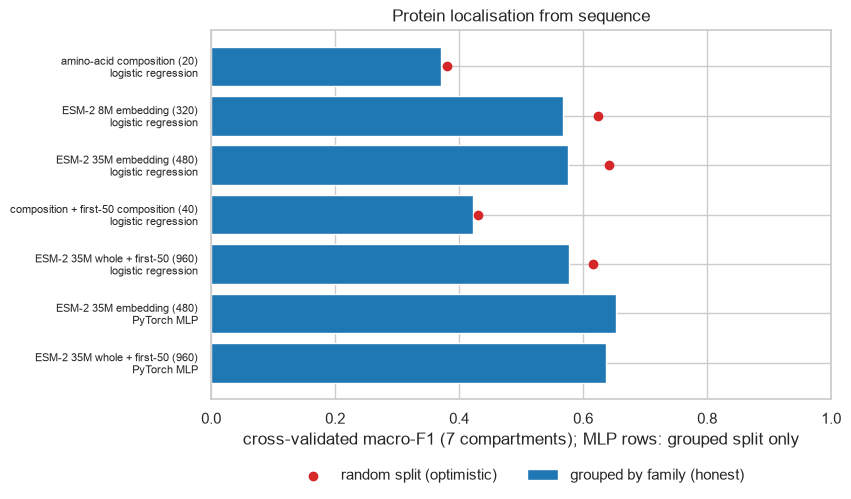

In [8]:
grouped = table[table["split"] == "grouped by family"].copy()
grouped["label"] = grouped["features"] + "\n" + grouped["model"]
rand = table[table["split"] == "random 5-fold"].set_index(["features", "model"])["macro-F1"]
grouped["random"] = [
    rand.get((f, m), np.nan) for f, m in zip(grouped["features"], grouped["model"], strict=True)
]

fig, ax = plt.subplots(figsize=(8, 4.8))
ypos = np.arange(len(grouped))
ax.barh(ypos, grouped["macro-F1"], color="tab:blue", label="grouped by family (honest)")
ax.scatter(grouped["random"], ypos, color="tab:red", zorder=3, label="random split (optimistic)")
ax.set_yticks(ypos, grouped["label"], fontsize=8)
ax.invert_yaxis()
ax.set(
    xlabel="cross-validated macro-F1 (7 compartments); MLP rows: grouped split only",
    xlim=(0, 1),
    title="Protein localisation from sequence",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
fig.savefig(FIGURES / "05_localisation_models.png", dpi=150, bbox_inches="tight")
plt.show()

## 6 · Where it goes wrong, and what the embedding space looks like

best grouped model: ESM-2 35M embedding (480) | PyTorch MLP
                       precision    recall  f1-score   support

              nucleus      0.755     0.758     0.757      1233
            cytoplasm      0.598     0.701     0.646      1189
        cell membrane      0.789     0.792     0.791       906
        mitochondrion      0.806     0.690     0.744       546
             secreted      0.785     0.794     0.789       436
endoplasmic reticulum      0.559     0.494     0.525       362
      Golgi apparatus      0.512     0.234     0.321       184

             accuracy                          0.707      4856
            macro avg      0.686     0.638     0.653      4856
         weighted avg      0.707     0.707     0.703      4856



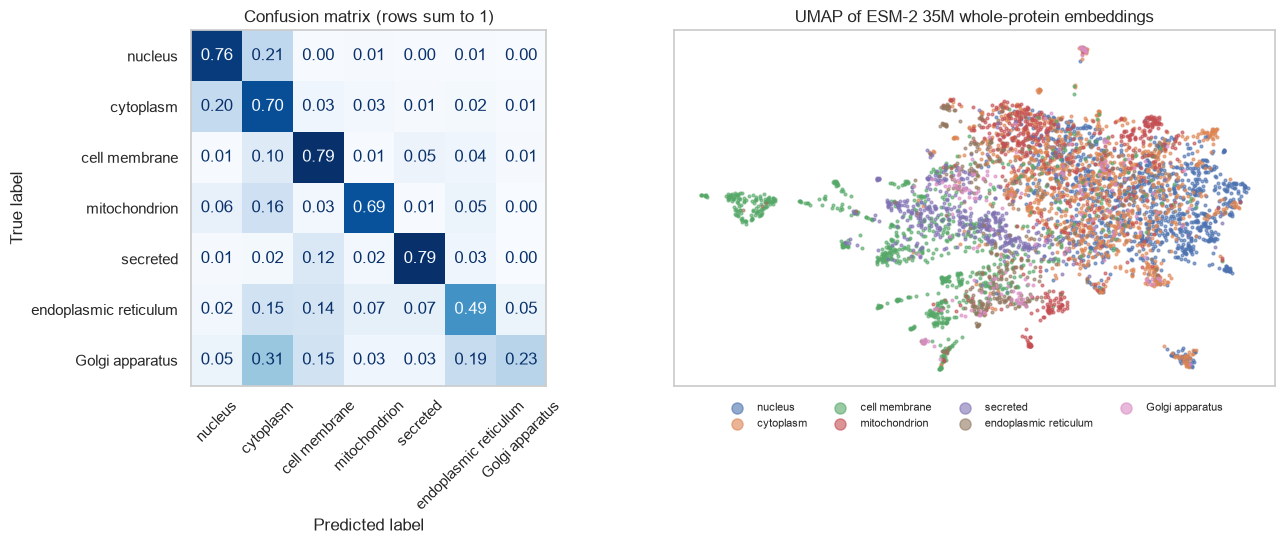

In [9]:
best_row = grouped.loc[grouped["macro-F1"].idxmax()]
print("best grouped model:", best_row["features"], "|", best_row["model"])
assert best_row["model"] == "PyTorch MLP", "re-derive predictions for the best model here"
best_pred = mlp_preds[best_row["features"]]
print(classification_report(y, best_pred, target_names=CLASSES, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
ConfusionMatrixDisplay.from_predictions(y, best_pred, display_labels=CLASSES, normalize="true", values_format=".2f",
                                        cmap="Blues", colorbar=False, ax=axes[0], xticks_rotation=45)  # fmt: skip
axes[0].set_title("Confusion matrix (rows sum to 1)")
axes[0].grid(False)
xy = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=SEED).fit_transform(
    StandardScaler().fit_transform(embeddings[best_esm])
)
for k, c in enumerate(CLASSES):
    m = y == k
    axes[1].scatter(xy[m, 0], xy[m, 1], s=4, alpha=0.6, label=c)
axes[1].set(title=f"UMAP of {best_esm} whole-protein embeddings", xticks=[], yticks=[])
axes[1].legend(
    markerscale=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False
)
fig.tight_layout()
fig.savefig(FIGURES / "06_localisation_errors_and_map.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the errors** (best honest model: MLP on ESM-2 35M embeddings, macro-F1 0.653)

* **Strongest: cell membrane (F1 0.79), secreted (0.79), nucleus (0.76), mitochondrion (0.74).** These are the
  compartments with clear, well-known sequence signals: signal peptides, water-repelling membrane-crossing segments,
  nuclear localisation signals, mitochondrial transit peptides. On the map, membrane proteins (green) form their own
  regions, and secreted proteins (purple) sit next to them. Both use the same entry route, the signal peptide.
* **Nucleus vs cytoplasm is the biggest confusion** (about 20 % of each predicted as the other). Many proteins shuttle
  between the two, and the switch is often controlled by modifications, not the sequence. On the map, the two are
  thoroughly mixed.
* **Golgi apparatus is the hardest (recall 0.23, F1 0.32).** It's the smallest class (184 proteins), and Golgi,
  endoplasmic reticulum and membrane proteins all travel the same secretory pathway. The signals that keep a protein
  *in* the Golgi are subtle and not fully understood. Golgi proteins are most often predicted as cytoplasm (31 %),
  endoplasmic reticulum (19 %) or cell membrane (15 %).
* **The endoplasmic reticulum is second-hardest (F1 0.53)**, for the same reason: it shares the secretory route.

## Conclusions

1. **Same tools, new kind of "language":** the `dsls.textclf` network and training loop from notebook 01 worked
   unchanged on protein embeddings. The engineering pays off when the next problem arrives.
2. **Protein language models are a big step up:** embeddings from an 8-million-parameter ESM-2 raise honest
   macro-F1 from 0.37 (amino-acid composition) to 0.57, with no fine-tuning; a small network on top reaches 0.65.
   Whether a network beats a linear model depends on the features: it tied on word counts, and won here.
3. **Grouped evaluation matters more as features improve:** random splits added up to +0.07 for ESM-2 embeddings
   but only +0.01 for composition. Family grouping is the minimum; clustering by sequence identity would be stricter.
4. **Domain knowledge must be tested:** looking at the N-terminus helped the crude baseline (+0.05) and did nothing
   for ESM-2, which already reads the targeting signal.
5. **Bigger isn't automatically better:** ESM-2 35M beat 8M by under 0.01 at twice the cost.
6. **Seed everything that is random:** unseeded starting weights moved the score by 0.015 between identical runs.
   `MLPClassifier` now takes a `seed`, and a unit test checks it.
7. **Know the label limits:** labels are experimental, single-compartment annotations. Proteins that move between
   compartments are excluded, so real-world accuracy on all proteins would be lower.

*Data: UniProtKB/Swiss-Prot ([CC BY 4.0](https://www.uniprot.org/help/license)), fetched through the cached EBI
client in [`src/dsls/ebi_api.py`](../../../src/dsls/ebi_api.py); location parsing in
[`src/dsls/protein.py`](../../../src/dsls/protein.py) (unit-tested). ESM-2 weights: Meta AI, MIT licence, from the
Hugging Face hub. Runtime: about 5 minutes the first time (embedding), then under 2 minutes from the cache.*